In [20]:

# 1. Import libraries and project classes

import numpy as np
import pandas as pd
import statistics
import matplotlib.pyplot as plt
import math

from pathlib import Path
import sys

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Make the src folder available for package imports
project_root = Path.cwd()

if not (project_root / "src" / "ubos_forecaster").exists():
    project_root = project_root.parent

sys.path.insert(0, str(project_root / "src"))

# Import our reusable classes
from ubos_forecaster import (
    DistrictPopulation,
    Forecaster,
    LinearTrendForecaster,
    CAGRForecaster,
    FibonacciForecaster,
    bootstrap_prediction_intervals,
)

In [21]:

# 2. Define the years and district population data

years = np.arange(2015, 2025)

# Population estimates, in thousands of people
population_data = {
    "Kampala": [1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800],
    "Wakiso":  [950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670],
    "Gulu":    [320, 330, 345, 360, 375, 390, 410, 430, 455, 480],
    "Mbarara": [475, 479, 480, 490, 495, 500, 520, 550, 570, 600],
    "Mbale":   [800, 816, 823, 851, 865, 908, 920, 940, 960, 980],
}

print("Years:", years)
print("Number of years:", len(years))
print("Districts:", list(population_data.keys()))

# Check that every district has one observation per year
for district, populations in population_data.items():
    print(f"{district}: {len(populations)} observations")
    assert len(populations) == len(years)


Years: [2015 2016 2017 2018 2019 2020 2021 2022 2023 2024]
Number of years: 10
Districts: ['Kampala', 'Wakiso', 'Gulu', 'Mbarara', 'Mbale']
Kampala: 10 observations
Wakiso: 10 observations
Gulu: 10 observations
Mbarara: 10 observations
Mbale: 10 observations


In [22]:

# 3. Display the population data in tabular form
population_df = pd.DataFrame(population_data, index=years) # organises the population data into a table and index assigns the years 2015–2024 as row labels.
population_df.index.name = "Year" # labels the index.
population_df


,Kampala,Wakiso,Gulu,Mbarara,Mbale
Year,,,,,
2015,1200,950,320,475,800
2016,1250,1000,330,479,816
2017,1300,1070,345,480,823
2018,1350,1150,360,490,851
2019,1420,1220,375,495,865
2020,1500,1300,390,500,908
2021,1580,1390,410,520,920
2022,1650,1480,430,550,940
2023,1720,1570,455,570,960


In [23]:

# 4. Create DistrictPopulation objects for all five districts

districts = {}

for name, populations in population_data.items():
    districts[name] = DistrictPopulation(
        name=name,
        years=years,
        populations=populations)

# Display the district objects
for district in districts.values():
    print(district)

DistrictPopulation(name='Kampala', N=10 records, years=2015-2024)
DistrictPopulation(name='Wakiso', N=10 records, years=2015-2024)
DistrictPopulation(name='Gulu', N=10 records, years=2015-2024)
DistrictPopulation(name='Mbarara', N=10 records, years=2015-2024)
DistrictPopulation(name='Mbale', N=10 records, years=2015-2024)


In [24]:

# 5. Inspect a district object demonstrates encapsulation

kampala = districts["Kampala"]

print("District object:", kampala)
print("District name:", kampala.name) # Accesses an object attribute
print("Years:", kampala.years)        # Retrieves the years stored in the object
print("Population array:", kampala.populations) # Retrieves its population data
print("Number of observations:", len(kampala)) # Calls your __len__() method
print("Object representation:", repr(kampala))  # Calls your __repr__() method


District object: DistrictPopulation(name='Kampala', N=10 records, years=2015-2024)
District name: Kampala
Years: [2015 2016 2017 2018 2019 2020 2021 2022 2023 2024]
Population array: [1200. 1250. 1300. 1350. 1420. 1500. 1580. 1650. 1720. 1800.]
Number of observations: 10
Object representation: DistrictPopulation(name='Kampala', N=10 records, years=2015-2024)


In [25]:

# 6. Calculate descriptive statistics for all five districts

results = []

for name, district in districts.items():
    data = district.populations

    results.append({
        "District": name,
        "Mean": statistics.mean(data), # Average population over 2015–2024
        "Median": statistics.median(data), # Middle population value after ordering the observations
        "Sample Variance": statistics.variance(data), # How dispersed the observations are around their mean, in squared units
        "Sample SD": statistics.stdev(data) # Population dispersion in the original units (thousands of people)
    })

statistics_df = pd.DataFrame(results)

statistics_df.round(6)
# statistics_df.to_excel('descriptive_mini1.xlsx')

,District,Mean,Median,Sample Variance,Sample SD
0,Kampala,1477.0,1460.0,42601.111111,206.400366
1,Wakiso,1280.0,1260.0,60066.666667,245.085019
2,Gulu,389.5,382.5,2885.833333,53.719953
3,Mbarara,515.9,497.5,1873.655556,43.285743
4,Mbale,886.3,886.5,4088.677778,63.942770


Interpret the descriptive statistics

* Kampala - Highest average population and substantial variation over time.
* Wakiso - Highest standard deviation, indicating the greatest absolute variation.
* Gulu - Lower average population and comparatively lower absolute variation.
* Mbarara - Moderate average population with relatively low variation.
* Mbale - Higher average population than Gulu and Mbarara, with moderate variation.

Key findings

1. Kampala has the highest mean population, at 1,477 thousand people.
2. Wakiso has the greatest variability, with a sample standard deviation of approximately 245.09 thousand people.
3. Mbarara has the lowest standard deviation, approximately 43.29 thousand people, meaning its population figures are less dispersed in absolute terms over the observed period.

`NOTE`: Mbarara and Mbale use illustrative practice figures, so those findings should not be presented as official population estimates.

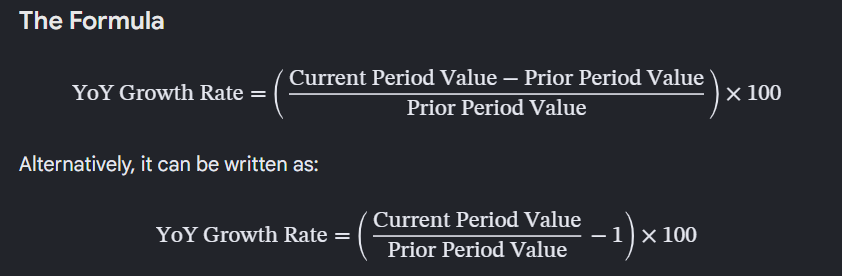

In [26]:

# 7. Calculate year-on-year population growth
# we will use the year_on_year_growth() method you added to DistrictPopulation.
growth_results = []

for name, district in districts.items():
    growth_rates = district.year_on_year_growth()

    for i, rate in enumerate(growth_rates):
        growth_results.append({
            "District": name,
            "Year": district.years[i + 1],
            "Growth rate (%)": rate
        })

growth_df = pd.DataFrame(growth_results)
growth_df.round(6)
# growth_df.to_excel('YoYmini1.xlsx')
growth_df.head()

,District,Year,Growth rate (%)
0,Kampala,2016,4.166667
1,Kampala,2017,4.000000
2,Kampala,2018,3.846154
3,Kampala,2019,5.185185
4,Kampala,2020,5.633803


Interpretation of  the growth rates

- Wakiso has consistently high annual growth, including 7.48% in 2018 and 6.92% in 2021.
- Kampala shows relatively steady annual growth, ranging from about 3.85% to 5.63%.
- Gulu has mostly moderate growth, with its highest rate of about 5.81% in 2023.
- Mbarara has lower growth in the earlier years, followed by faster growth in later years.
- Mbale shows positive growth throughout the period, with some variation in the annual rate.

8. Calculate CAGR for all five districts

CAGR summarises the compounded growth between the first and last years.

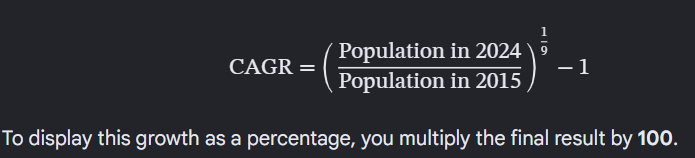

We divide by nine years because 2015–2024 contains nine annual intervals, even though there are ten observations.

In [27]:

# 8. Calculate CAGR for all five districts

cagr_results = []

for name, district in districts.items():
    cagr_results.append({
        "District": name,
        "2015 Population ('000s)": district.populations[0],
        "2024 Population ('000s)": district.populations[-1],
        "CAGR (%)": district.cagr()
    })

cagr_df = pd.DataFrame(cagr_results)
cagr_df.round(6)
# cagr_df.to_excel('CAGRmini1.xlsx')
cagr_df.head()

,District,2015 Population ('000s),2024 Population ('000s),CAGR (%)
0,Kampala,1200.0,1800.0,4.608192
1,Wakiso,950.0,1670.0,6.468572
2,Gulu,320.0,480.0,4.608192
3,Mbarara,475.0,600.0,2.629703
4,Mbale,800.0,980.0,2.280513


Key finding: Wakiso had the fastest relative population growth, with a CAGR of approximately 6.47% per year. Kampala and Gulu both had a CAGR of approximately 4.61%.

9 : Visualise historical population trends

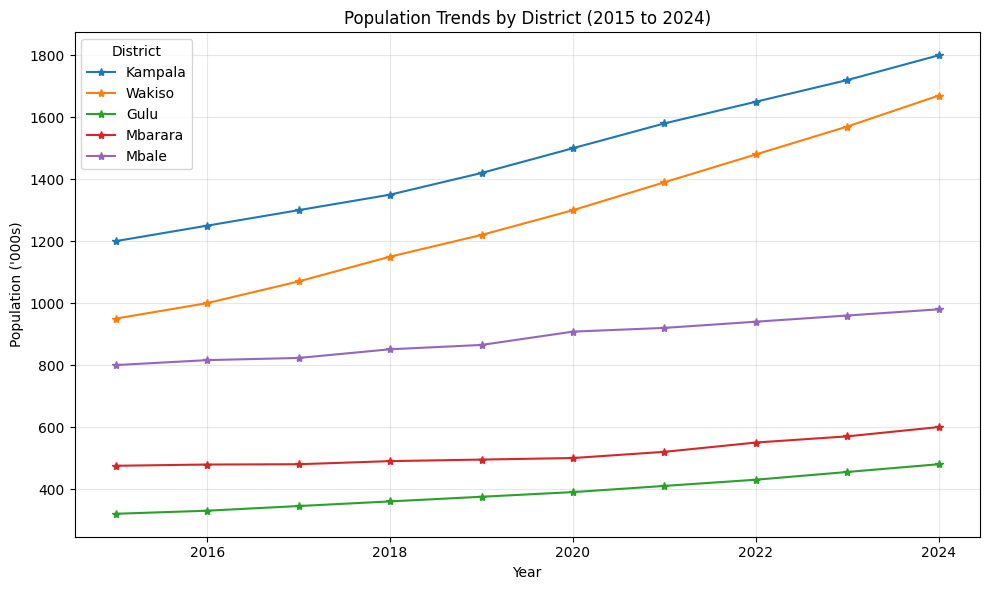

In [28]:

# 9. Visualise population trends from 2015 to 2024

ax = population_df.plot(kind="line",marker="*", figsize=(10, 6))

ax.set_title("Population Trends by District (2015 to 2024)")
ax.set_xlabel("Year")
ax.set_ylabel("Population ('000s)")
ax.legend(title="District")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


* Population size: Kampala has the largest population throughout the period.
* Relative growth: Wakiso has the highest CAGR.
* Trend direction: All five illustrative series increase from 2015 to 2024.
* Data limitation: Mbarara and Mbale use illustrative practice data, not official population estimates.

10 : training and testing periods

We will preserve the split from your recovered notebook:
- Training: 2015–2021 (7 observations).
- Testing: 2022–2024 (3 observations).

In [29]:

# 10. Define the training and testing periods

train_mask = (years >= 2015) & (years <= 2021)
test_mask = (years >= 2022) & (years <= 2024)

train_years = years[train_mask]
test_years = years[test_mask]

print("Training years:", train_years)
print("Testing years:", test_years)
print("Training observations:", len(train_years))
print("Testing observations:", len(test_years))


Training years: [2015 2016 2017 2018 2019 2020 2021]
Testing years: [2022 2023 2024]
Training observations: 7
Testing observations: 3


11 : Test the three forecasting models on Kampala

We will verify that each model can fit the training data and produce three predictions for 2022–2024.

In [30]:

# 11. Test all three forecasting models on Kampala

model_classes = {
    "Linear Trend": LinearTrendForecaster,
    "CAGR": CAGRForecaster,
    "Fibonacci Ratio": FibonacciForecaster
}

kampala = districts["Kampala"]

train_mask = (kampala.years >= 2015) & (kampala.years <= 2021)

kampala_train_years = kampala.years[train_mask]
kampala_train_values = kampala.populations[train_mask]

for model_name, model_class in model_classes.items():
    model = model_class()

    model.fit(kampala_train_years, kampala_train_values)

    predictions = model.predict(3)

    print(f"\n{model_name}")
    print("Predictions for 2022–2024:", np.round(predictions, 3))



Linear Trend
Predictions for 2022–2024: [1622.857 1685.714 1748.571]

CAGR
Predictions for 2022–2024: [1654.13  1731.739 1812.988]

Fibonacci Ratio
Predictions for 2022–2024: [1580. 3160. 2370.]


- Linear Trend: estimates a straight line from the training data.
- CAGR: estimates a constant compounded annual growth rate.
- Fibonacci Ratio: applies the experimental Fibonacci-ratio rule we recovered earlier.
- `limitation` - The Fibonacci implementation is experimental. Its raw ratios can produce unrealistic predictions; we will assess that through validation rather than assuming it is a good forecasting method.

Findings: The linear trend and CAGR predictions are relatively close to the actual populations. The Fibonacci model predicts 3,160 thousand for 2023 because it multiplies the final training value by the raw Fibonacci ratio of 2. This illustrates why we need to evaluate the models against observations they did not train on.

12 : Validate all three models across the five districts

In [31]:

# 12. Validate all forecasting models across all districts

validation_results = []

for district_name, district in districts.items():
    years_all = district.years
    values_all = district.populations

    train_mask = (years_all >= 2015) & (years_all <= 2021)
    test_mask = (years_all >= 2022) & (years_all <= 2024)

    train_years = years_all[train_mask]
    train_values = values_all[train_mask]
    test_values = values_all[test_mask]

    for model_name, model_class in model_classes.items():
        model = model_class()
        model.fit(train_years, train_values)

        predictions = model.predict(len(test_values))

        mae = mean_absolute_error(test_values, predictions)
        rmse = np.sqrt(mean_squared_error(test_values, predictions))
        mape = np.mean(np.abs((test_values - predictions) / test_values)) * 100

        validation_results.append({
            "District": district_name,
            "Model": model_name,
            "MAE": mae,
            "RMSE": rmse,
            "MAPE (%)": mape
        })

validation_df = pd.DataFrame(validation_results)
validation_df.round(6)
# validation_df.to_excel('validation.xlsx')
validation_df.head()


,District,Model,MAE,RMSE,MAPE (%)
0,Kampala,Linear Trend,37.619048,38.974961,2.165173
1,Kampala,CAGR,9.619128,10.385147,0.551460
2,Kampala,Fibonacci Ratio,693.333333,895.060519,39.876674
3,Wakiso,Linear Trend,49.404762,52.367828,3.093815
4,Wakiso,CAGR,6.801562,8.049068,0.420107


Interpretation: CAGR performs best for Kampala, Wakiso, Gulu and Mbarara. Linear Trend performs best for Mbale. The Fibonacci Ratio model performs poorly across all five districts under its current implementation.

In [32]:
# Select the model with the lowest MAPE for each district
best_model_df = (validation_df.loc[validation_df.groupby("District")["MAPE (%)"].idxmin()].sort_values("District").reset_index(drop=True))
best_model_df.round(6)
# best_model_df.to_excel('best_model.xlsx')
best_model_df.head()

,District,Model,MAE,RMSE,MAPE (%)
0,Gulu,CAGR,9.437351,10.869351,2.024973
1,Kampala,CAGR,9.619128,10.385147,0.551460
2,Mbale,Linear Trend,0.833333,0.994030,0.087764
3,Mbarara,CAGR,37.364504,39.903241,6.438638
4,Wakiso,CAGR,6.801562,8.049068,0.420107


We will then use those selected models to forecast population for 2025–2029, fitting each selected model to the full 2015–2024 historical data.

3: Forecast population for 2025–2029

In [33]:
# Forecast population for the next five years
forecast_years = np.arange(2025, 2030)

# Models selected using the lowest validation MAPE
best_model_classes = {
    "Kampala": CAGRForecaster,
    "Wakiso": CAGRForecaster,
    "Gulu": CAGRForecaster,
    "Mbarara": CAGRForecaster,
    "Mbale": LinearTrendForecaster,
}

forecast_results = []

for district_name, district in districts.items():
    model_class = best_model_classes[district_name]

    # Fit the selected model using all historical observations
    model = model_class()
    model.fit(district.years, district.populations)

    # Forecast the next five years
    predictions = model.predict(len(forecast_years))

    # Save the forecasts
    for year, prediction in zip(forecast_years, predictions):
        forecast_results.append({
            "District": district_name,
            "Year": year,
            "Forecast Population ('000s)": prediction,
            "Forecast Population (people)": round(prediction * 1000)
        })

forecast_df = pd.DataFrame(forecast_results)

forecast_df.round(6)
# forecast_df.to_excel('forecast.xlsx')
forecast_df.head()

,District,Year,Forecast Population ('000s),Forecast Population (people)
0,Kampala,2025,1882.947454,1882947
1,Kampala,2026,1969.717285,1969717
2,Kampala,2027,2060.485637,2060486
3,Kampala,2028,2155.436768,2155437
4,Kampala,2029,2254.763430,2254763


- Uses CAGR for Kampala, Wakiso, Gulu and Mbarara.
- Uses Linear Trend for Mbale.
- Fits each model to all ten observations from 2015–2024.
- Forecasts five years, from 2025 through 2029.
- Displays population both in thousands and as estimated numbers of people.

Limitation: These are model-based projections using illustrative historical data, not official UBOS population forecasts.

4: Visualize historical population and forecasts

This chart will show the actual population from 2015–2024 and the forecast from 2025–2029 for each district.

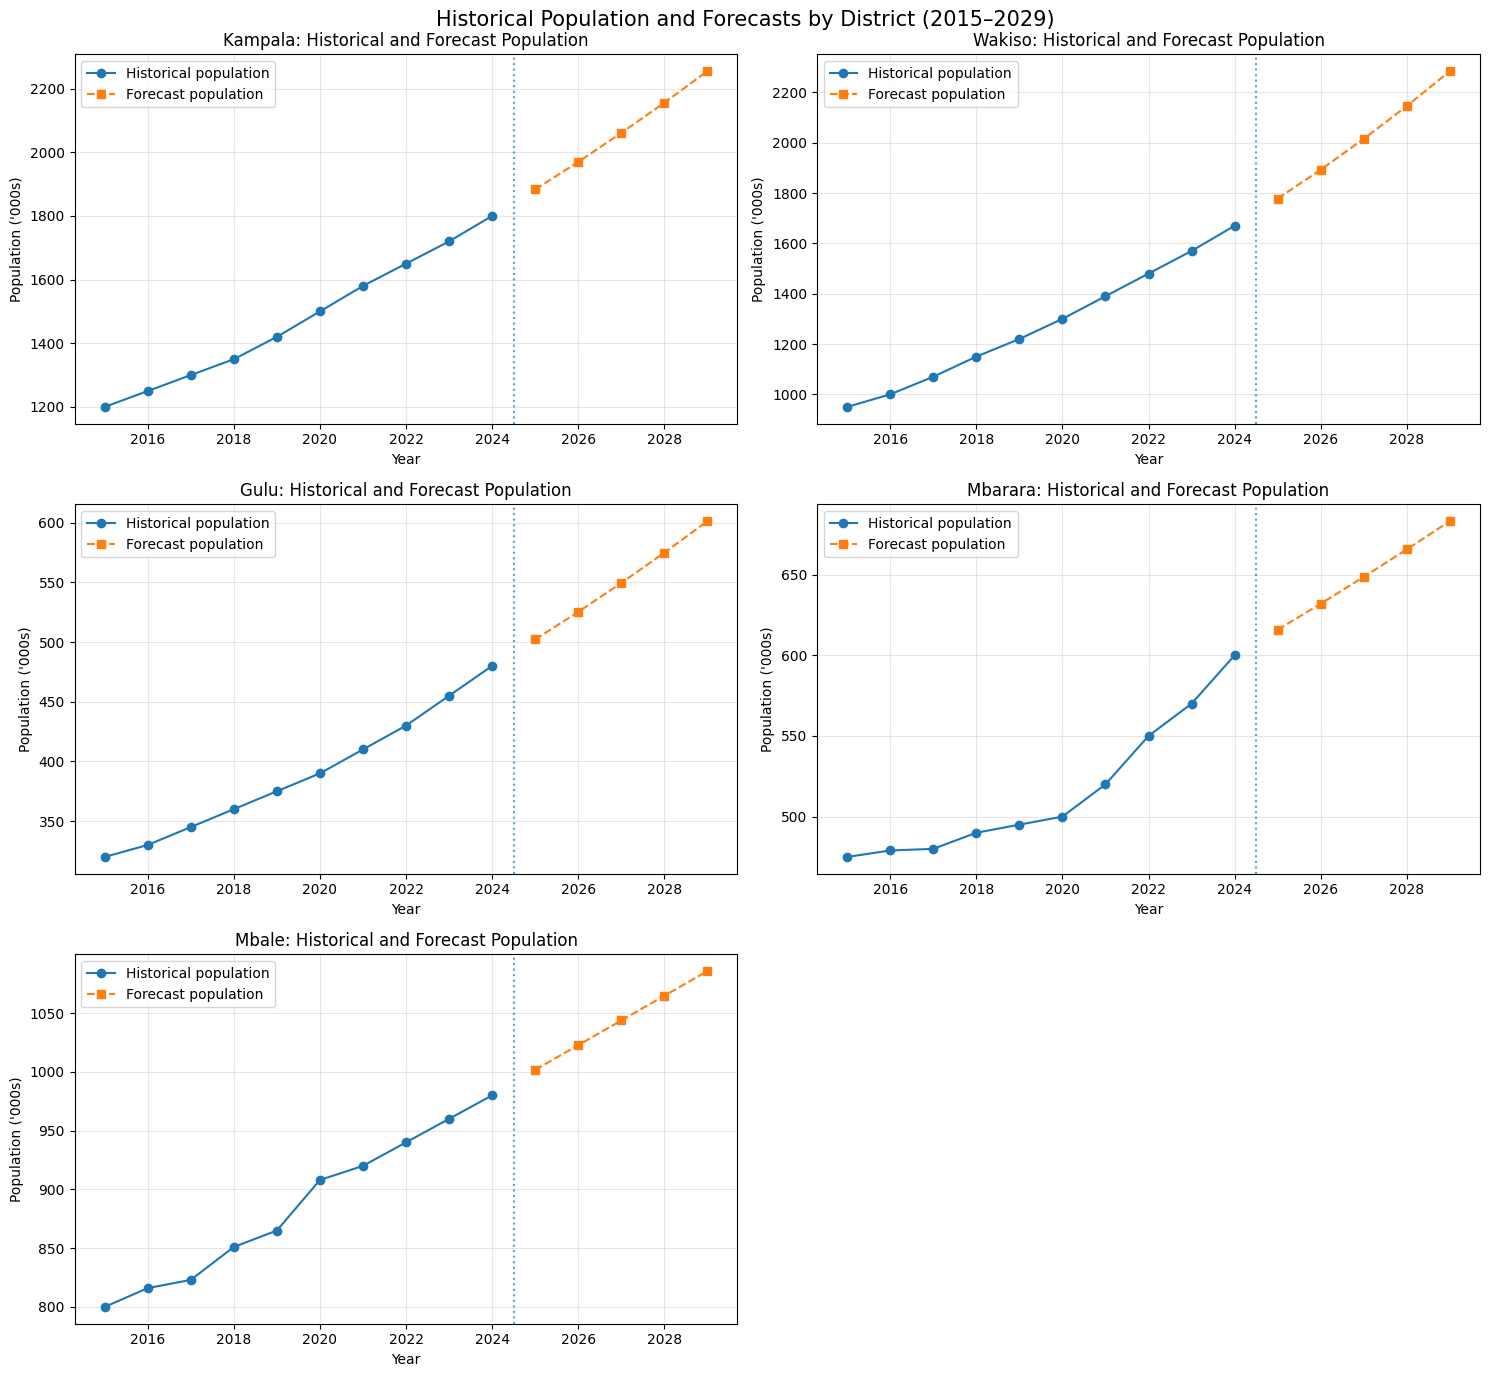

In [34]:
fig, axes = plt.subplots(3, 2, figsize=(15, 14))
axes = axes.flatten()

for i, (district_name, district) in enumerate(districts.items()):
    ax = axes[i]
    # Historical population
    ax.plot(district.years, district.populations,  marker="o",  label="Historical population")

    # Forecast population
    district_forecast = forecast_df[forecast_df["District"] == district_name]

    ax.plot(district_forecast["Year"], district_forecast["Forecast Population ('000s)"], marker="s", linestyle="--", label="Forecast population")

    # Mark the beginning of the forecast period
    ax.axvline(x=2024.5, linestyle=":", alpha=0.7)

    ax.set_title(f"{district_name}: Historical and Forecast Population")
    ax.set_xlabel("Year")
    ax.set_ylabel("Population ('000s)")
    ax.grid(True, alpha=0.3)
    ax.legend()

# Remove the unused sixth subplot
fig.delaxes(axes[5])

plt.suptitle("Historical Population and Forecasts by District (2015–2029)",fontsize=15)
plt.tight_layout()
plt.show()

- The solid lines show historical observations.
- The dashed lines show forecasts for 2025-2029.
- The vertical dotted line separates historical data from projections.
- Kampala and Wakiso have the largest projected populations, while Gulu has the smallest among these five districts.

5: Applying the classroom-planning scenario

Assumptions

Estimate primary-school-age children and additional classrooms

1. The projected increase in population from 2024 to 2029.
2. The estimated number of primary-school-age children, assuming 18% of the population.
3. The estimated additional classrooms required, assuming 53 pupils per classroom.

In [35]:
# Classroom planning assumptions
primary_school_age_share = 0.18
pupils_per_classroom = 53

classroom_results = []

for district_name, district in districts.items():

    # Actual population in 2024
    population_2024 = district.populations[-1] * 1000

    # Forecast population in 2029
    population_2029 = forecast_df.loc[(forecast_df["District"] == district_name) & (forecast_df["Year"] == 2029),   "Forecast Population (people)"].iloc[0]

    # Estimated primary-school-age children
    primary_children_2024 = (population_2024 * primary_school_age_share)
    primary_children_2029 = (population_2029 * primary_school_age_share)

    # Increase in primary-school-age children
    additional_children = (primary_children_2029 - primary_children_2024)

    # Additional classrooms needed because of population growth
    additional_classrooms = np.ceil(max(0, additional_children) / pupils_per_classroom)

    # Total classroom capacity required in 2029
    total_classrooms_2029 = np.ceil(primary_children_2029 / pupils_per_classroom)

    classroom_results.append({
        "District": district_name,
        "Population 2024": round(population_2024),
        "Population 2029": round(population_2029),
        "Primary Children 2024": round(primary_children_2024),
        "Primary Children 2029": round(primary_children_2029),
        "Additional Children": round(additional_children),
        "Additional Classrooms": int(additional_classrooms),
        "Total Classrooms Required 2029": int(total_classrooms_2029)
    })

classroom_df = pd.DataFrame(classroom_results)
# classroom_df.to_excel('classrooms.xlsx')
classroom_df.head()

,District,Population 2024,Population 2029,Primary Children 2024,Primary Children 2029,Additional Children,Additional Classrooms,Total Classrooms Required 2029
0,Kampala,1800000,2254763,324000,405857,81857,1545,7658
1,Wakiso,1670000,2284671,300600,411241,110641,2088,7760
2,Gulu,480000,601270,86400,108229,21829,412,2043
3,Mbarara,600000,683151,108000,122967,14967,283,2321
4,Mbale,980000,1085685,176400,195423,19023,359,3688


Key findings

- Wakiso has the largest projected increase in demand. It would require an estimated 2,088 additional classrooms under the case-study assumptions.
- Kampala follows, with an estimated 1,545 additional classrooms.
- Mbarara has the lowest additional classroom requirement, at 283 classrooms.
- Across the five illustrative districts, projected population growth implies approximately 4,687 additional classrooms by 2029, assuming 18% of the population is of primary-school age and each classroom accommodates 53 pupils.

Important distinction: The 4,687 figure represents additional classroom capacity associated with projected growth, not the existing classroom deficit. Determining the actual shortage would require data on existing classrooms, current enrolment, and school-age children not currently attending school.

7: Create a visualization for classroom planning

This makes the district-level planning implications easy to communicate in your presentation.

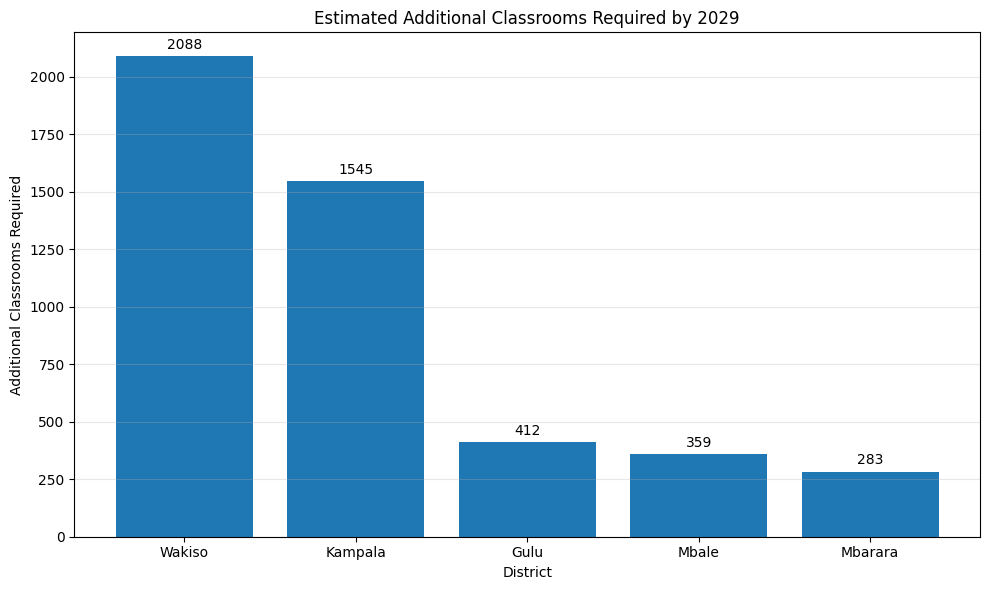

In [36]:
# Sort districts by additional classroom requirement
classroom_plot_df = classroom_df.sort_values("Additional Classrooms", ascending=False)

plt.figure(figsize=(10, 6))

bars = plt.bar(classroom_plot_df["District"], classroom_plot_df["Additional Classrooms"])

plt.title("Estimated Additional Classrooms Required by 2029")
plt.xlabel("District")
plt.ylabel("Additional Classrooms Required")
plt.grid(axis="y", alpha=0.3)

# Display values above the bars
plt.bar_label(bars, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

In [37]:
# 3: Calculate prediction intervals for all five districts
# Store forecasts and 95% bootstrap prediction intervals
interval_results = []

for district_name, district in districts.items():

    # Use the model selected during validation
    model_class = best_model_classes[district_name]
    model = model_class()

    # Fit using all historical data (2015–2024)
    model.fit(district.years, district.populations)

    # Calculate forecasts and 95% prediction intervals
    point, lower, upper = bootstrap_prediction_intervals( model=model,   years=district.years,   values=district.populations,  horizon=5,   n_resamples=1000,   seed=42,)

    # Store each forecast year
    for year, forecast, low, high in zip(forecast_years, point, lower, upper):
        interval_results.append({
            "District": district_name,
            "Year": year,
            "Forecast ('000s)": forecast,
            "Lower 95% ('000s)": low,
            "Upper 95% ('000s)": high,
        })

interval_df = pd.DataFrame(interval_results)
interval_df.round(6)
# interval_df.to_excel('prediction_intervals.xlsx')
interval_df.head()

,District,Year,Forecast ('000s),Lower 95% ('000s),Upper 95% ('000s)
0,Kampala,2025,1882.947454,1864.319483,1895.531737
1,Kampala,2026,1969.717285,1951.089314,1982.301569
2,Kampala,2027,2060.485637,2041.857666,2073.069921
3,Kampala,2028,2155.436768,2136.808797,2168.021052
4,Kampala,2029,2254.763430,2236.135459,2267.347714


5: Shade the 95% prediction intervals on plot

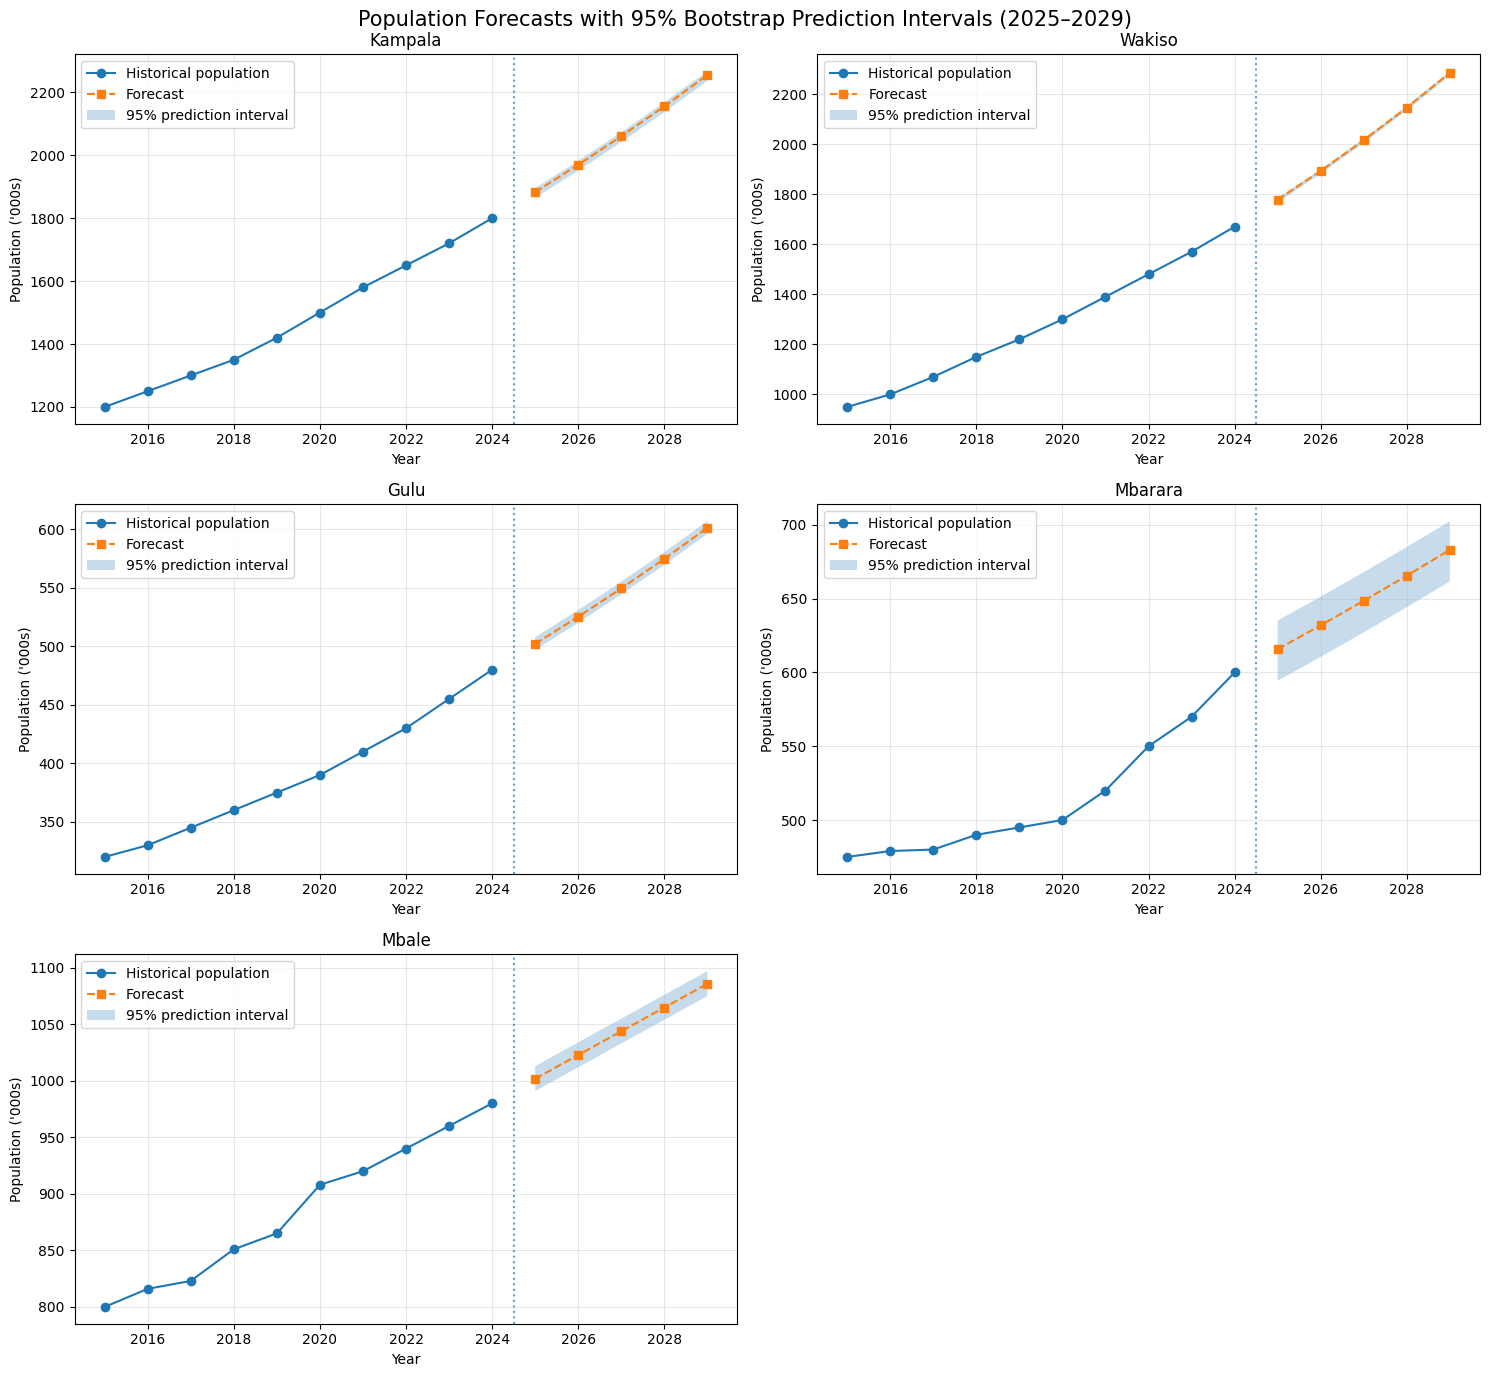

In [38]:
fig, axes = plt.subplots(3, 2, figsize=(15, 14))
axes = axes.flatten()

for i, (district_name, district) in enumerate(districts.items()):
    ax = axes[i]

    # Historical population
    ax.plot( district.years,  district.populations, marker="o", label="Historical population")

    # Forecasts and prediction intervals
    district_intervals = interval_df[interval_df["District"] == district_name].sort_values("Year")

    forecast_x = district_intervals["Year"].to_numpy()
    forecast_y = district_intervals["Forecast ('000s)"].to_numpy()
    lower_y = district_intervals["Lower 95% ('000s)"].to_numpy()
    upper_y = district_intervals["Upper 95% ('000s)"].to_numpy()

    ax.plot( forecast_x,  forecast_y,  marker="s",   linestyle="--",   label="Forecast")

    ax.fill_between(forecast_x,lower_y,  upper_y,   alpha=0.25, label="95% prediction interval")

    ax.axvline(x=2024.5, linestyle=":", alpha=0.7)

    ax.set_title(district_name)
    ax.set_xlabel("Year")
    ax.set_ylabel("Population ('000s)")
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.delaxes(axes[5])

plt.suptitle("Population Forecasts with 95% Bootstrap Prediction Intervals (2025–2029)", fontsize=15)
plt.tight_layout()
plt.show()

6: Critical assessment of the Fibonacci-ratio model


### Critical Assessment of the Fibonacci-Ratio Model

The Fibonacci-ratio model was included as an experimental forecasting approach. In the current implementation, Fibonacci ratios are applied directly to the last observed population rather than being derived from a validated demographic growth mechanism. This produces implausible forecast behaviour: 

the second forecast value is twice the last observed population, followed by a reduction in the scaling ratio. Such behaviour is not justified by the historical population series or by an established assumption about annual population growth.

The validation results also show that the Fibonacci-ratio model performs substantially worse than the Linear Trend and CAGR models across all five districts. Its high Mean Absolute Percentage Errors indicate that it is unsuitable for the current forecasting task.

A Fibonacci-based approach could only be defended if a clear theoretical rationale or empirical evidence established that Fibonacci-related ratios meaningfully represent the process being modelled. No such evidence is available in this illustrative case study. Therefore, the model is retained for comparison and critical evaluation but excluded from the final population forecasts.

This assessment is limited by the small dataset, the illustrative nature of some district observations, and the absence of external demographic evidence. Future work could investigate alternative models using longer, verified population series and evaluate their performance on observations not used during model fitting.


## Findings & Limitations

### Findings

The analysis examined historical population patterns in Kampala, Wakiso, Gulu, Mbarara and Mbale using annual observations from 2015 to 2024. Descriptive statistics showed that Kampala had the highest mean population, while Wakiso exhibited the greatest absolute variation in population levels. The compound annual growth rate (CAGR) analysis identified Wakiso as the fastest-growing district, at approximately 6.47% annually, compared with approximately 4.61% for Kampala and Gulu.

Forecast validation compared Linear Trend, CAGR and Fibonacci-Ratio models using MAE, RMSE and MAPE. CAGR performed best for Kampala, Wakiso, Gulu and Mbarara, while Linear Trend performed best for Mbale. The Fibonacci-Ratio model had substantially higher prediction errors and was excluded from the final forecasts. The five-year projections were also used to illustrate education-planning implications. Under the assumptions that 18% of the population is of primary-school age and each classroom accommodates 53 pupils, the five districts would require an estimated 4,687 additional classrooms to accommodate projected population growth between 2024 and 2029.

### Limitations

The population series are illustrative and should not be interpreted as official UBOS estimates. Only ten annual observations were available per district, limiting the ability to assess long-term demographic changes. The residual-bootstrap prediction intervals use historical in-sample errors and do not fully represent uncertainty in model parameters, changing growth rates or unexpected demographic events. The classroom estimates also assume a constant school-age population share and classroom capacity, without accounting for existing classrooms, enrolment, attendance or infrastructure deficits. Consequently, the forecasts demonstrate analytical methods and planning scenarios rather than definitive policy estimates. Further work should use verified population data, longer time series and additional validation before informing actual resource allocation.